<a href="https://colab.research.google.com/github/lujainalghamdi8105-dev/atlas-open-data-z-boson/blob/main/z_boson_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Find the Z boson yourself!
This notebook uses ATLAS Open Data to guide you through the steps to find the Z boson. It takes less than an hour to complete, and by the end, you’ll be able to identify the Z boson in ATLAS detector data from the 2015 and 2016 runs.

## The Z boson
In the [Standard Model of particle physics](https://opendata.atlas.cern/docs/documentation/introduction/SM_and_beyond) the Z boson is one of the two bosons responsible for mediating the weak interaction. It has a very short lifetime, of about $10^{-25}$ seconds, and decays via the weak force into leptons and quarks. Below you can see a [Feynman diagram](https://en.wikipedia.org/wiki/Feynman_diagram) of the decay of the Z boson into two leptons.


**Credit:** The tutorial parts of this notebook (data loading, the invariant mass calculation, and the first plot) are adapted from the ATLAS Open Data tutorial "Find the Z boson yourself!" (opendata.atlas.cern). That code is ATLAS's. My own work is the background explanation and everything under "Part 2: My analysis" at the end.

# Background: what I measured and why
The Z boson is a heavy particle, about 91 GeV, that is electrically neutral and carries the weak force, the same force behind beta radioactive decay. It lives for only about 10⁻²⁵ seconds, so it decays long before reaching any detector, and I can only study it through what it turns into. In my data, it decays into a muon and an antimuon, which are easy to identify because they pass through the whole ATLAS detector and leave clear tracks, unlike quarks, which produce messy sprays of particles. For each pair, I combine the two muons’ energies and momenta into one number, the invariant mass M, which equals the mass of the particle they came from. Pairs from a Z all give about 91 GeV, while unrelated pairs give random values, so the peak in my plot shows that many pairs shared the same parent.


<CENTER><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/feynman_diagrams/Zee_feynman.png?raw=1" style="width:40%"></CENTER>

<a id='contents'></a>

Due to its short lifetime, we don't measure the Z boson directly in the ATLAS detector. What we measure is its decays products (in this case the two leptons) and reconstruct its mass. Ready to learn how to do this? Let's go!.


## Running a Jupyter notebook

To run the whole Jupyter notebook, in the top menu click Cell $\rightarrow$ Run All.

To propagate a change you've made to a piece of code, click Cell $\rightarrow$ Run All Below.

You can also run a single code cell, by using the keyboard shortcut Shift+Enter.

## First time setup on your computer (no need on mybinder)
This first cell only needs to be run the first time you open this notebook on your computer.

If you close Jupyter and re-open it on the same computer, you won't need to run this first cell again.

If you open the notebook on mybinder, you don't need to run this cell.

In [1]:
#install required packages
import sys
%pip install atlasopenmagic
from atlasopenmagic import install_from_environment
install_from_environment()

Installing packages: ['aiohttp>=3.9.5', 'atlasopenmagic>=1.9.0', 'awkward>=2.6.7', 'awkward-pandas>=2023.8.0', 'coffea~=0.7.0', 'fsspec>=2025.7.0', 'hist>=2.8.0', 'ipykernel>=6.29.5', 'jupyter>=1.0.0', 'lmfit>=1.3.2', 'matplotlib>=3.9.1', 'metakernel>=0.30.2', 'notebook<7', 'numpy>=1.26.4', 'pandas>=2.2.2', 'papermill>=2.6.0', 'pip>=24.2', 'scikit-learn>=1.5.1', 'uproot>=5.3.10', 'uproot3>=3.14.4', 'fsspec-xrootd>=0.5.1', 'jupyterlab_latex~=3.1.0', 'vector>=1.4.1']
Installation complete. You may need to restart your Python environment for changes to take effect.


In [2]:
%pip install uproot awkward vector atlasopenmagic scipy

## To setup everytime
We're going to be using a number of tools to help us:
* urllib: let us download files
* uproot: lets us read .root files typically used in particle physics into data formats used in Python
* pandas: lets us store data as dataframes, a format widely used in Python
* numpy: provides numerical calculations such as histogramming
* matplotlib: common tool for making plots, figures, images, visualisations
* awkward: a python package for dealing conveniently with lists that are different lengths
* vector: a python package for making and manipulating vectors

In case you see an error when importing one of these packages, try restarting the kernel (the "session" in Colab) to make sure the packages that were installed in the last cell have been properly loaded.

In [3]:
%pip install uproot awkward vector atlasopenmagic

In [4]:
import urllib.request # for downloading files
import pandas as pd # to store data as dataframes
import numpy as np # for numerical calculations such as histogramming
import uproot # to read .root files as dataframes
import matplotlib.pyplot as plt # for plotting
from matplotlib.ticker import MaxNLocator,AutoMinorLocator # for minor ticks
import awkward as ak # for handling complex and nested data structures efficiently
import vector # For convenient 4-vector manipulation

/root/.local/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## Where's my data?

We're going to use a package called `atlasopenmagic` to find the data we want to use.

In [5]:
# Import the atlasopenmagic package so that we can use it
import atlasopenmagic as atom
# Make sure that we are using the newest release of Education and Outreach open data
atom.set_release('2025e-13tev-beta')
# We will use a skim (pre-selection) of the data so that we start from events
# with exactly two muons
skim = '2muons'
# And now we can get the files we want; note that we use "cache=True" to copy
# the files locally rather than streaming them
files_list = atom.get_urls('data', skim, protocol='https', cache=True)

Fetching metadata for release: 2025e-13tev-beta...
Fetching datasets: 100%|██████████| 374/374 [00:00<00:00, 883.43datasets/s]
✓ Successfully cached 374 datasets.
Active release: 2025e-13tev-beta. (Datasets path: REMOTE)


[Back to contents](#contents)

## Calculate that invariant mass!

In particle physics, the momentum of a particle is often written as a 4-vector: `(E, px, py, pz)`, where `E` is the energy of the particle, `px` is the momentum of the particle in the `x` direction, and so on. When we add them together, we add each component one-by-one. If a particle decays into two particles (for example, a Z boson decays into two leptons), then the sum of the 4-vectors of the two leptons is equal to the 4-vector of the original Z boson.

One other useful trick is that the mass of an object can easily be calculated from its 4-vector:

$$M^2=E^2-p^2,$$

where $p$ is the momentum $(px, py, pz)$. We are using "natural units" here, where the speed of light is 1 ($c=1$); if we weren't, that formula would be written:

$$(M \times c^2)^2=E^2-p^2,$$

That might start to look familiar. If a particle is at rest (it has no momentum, so $p=0$), that means:

$$(M \times c^2)^2 = E^2,$$

or simply

$$M \times c^2 = E$$

which is Einstein's famous formula!

The `vector` module has a handy way to put 4-vectors together. We can give it the components of the 4-momentum that we have, and it will conveniently put it into the `(E, px, py, pz)` form for us. In particle physics, and in our Open Data files, we store:

* `pt`, also written $p_\text{T}$, which is the part of the momentum transverse (perpendicular) to the beam's original direction ($p_\text{T}=\sqrt{px^2+py^2}$).
* `eta`, [pseudorapidity](https://en.wikipedia.org/wiki/Pseudorapidity), which is a convenient way to describe the angle of the particle's momentum in the detector.
* `phi`, the angle of the particle's momentum in the $x, y$ plane.
* `e`, the energy of the particle

We can stick these four components together and calculate all the others from them.

After that, all we have to do is add together the 4-momenta of the first two leptons, and then ask for the mass (also called the "invariant mass" because it doesn't matter how the particle is moving or if it is at rest, the mass is always the same).

In [6]:
# calculate dilepton invariant mass
def calc_mll(lep_pt,lep_eta,lep_phi,lep_e):
    p4 = vector.zip({"pt": lep_pt, "eta": lep_eta, "phi": lep_phi, "e": lep_e})
    invariant_mass = (p4[:, 0] + p4[:, 1]).M # .M calculates the invariant mass
    return invariant_mass

## Can we process the data yet?!

In [7]:
mass_list = [] # This list will hold all our output masses

# Loop through all the files that we have
for afile in files_list:
    print(f'Working on file {afile} ({files_list.index(afile)}/{len(files_list)})')

    tree = uproot.open(afile+":analysis") # open the file, and the tree called mini
    numevents = tree.num_entries # number of events

    for data in tree.iterate(['lep_pt','lep_eta','lep_phi','lep_e'],
                             library="ak"):
        # calculation of 2-lepton invariant mass
        data['mll'] = calc_mll(data.lep_pt, data.lep_eta, data.lep_phi, data.lep_e)
        # Keep the mll as a flat array
        mass_list.append( data['mll'] )
    # For simplicity and speed, we'll just work with the first file to start
    # Stop here!
    break

Working on file simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_2muons_data15_periodD.2muons.root (0/16)


## Function to plot the data

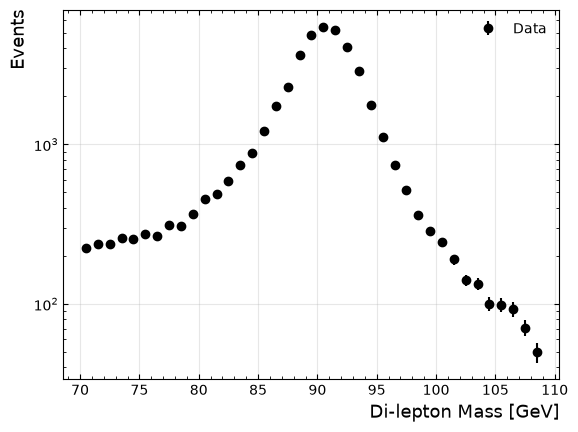

In [8]:
# In case we ran over multiple files / batches, merge them together
full_mass_list = ak.concatenate(mass_list)

bin_edges = np.arange(start=70, # The interval includes this value
                      stop=110, # The interval doesn't include this value
                      step=1 ) # Spacing between values
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2 # central values of each bin

# histogram the data
data_x,_ = np.histogram(full_mass_list, bins=bin_edges )

# statistical error on the data
data_x_errors = np.sqrt(data_x)

# get current axes
main_axes = plt.gca()

# plot the data points
main_axes.errorbar(x=bin_centres,
                   y=data_x,
                   yerr=data_x_errors,
                   fmt='ko',  # 'k' means black and 'o' is for circles
                   label = 'Data')

# set the axis tick parameters for the main axes
main_axes.tick_params(which='both', # ticks on both x and y axes
                        direction='in', # Put ticks inside and outside the axes
                        top=True, # draw ticks on the top axis
                        right=True ) # draw ticks on right axis

# x-axis label
main_axes.set_xlabel('Di-lepton Mass [GeV]', fontsize=13, x=1, horizontalalignment='right')

# y-axis label
main_axes.set_ylabel('Events', fontsize=13, y=1, horizontalalignment='right')

# make the y-axis log scale
main_axes.set_yscale('log')

# add minor ticks on x-axis for main axes
main_axes.xaxis.set_minor_locator( AutoMinorLocator() )

# draw the legend
main_axes.legend( frameon=False ); # no box around the legend
main_axes.grid(True, alpha=0.3)

## Part 2: My analysis

In [9]:
from scipy.optimize import curve_fit

counts = np.asarray(data_x, dtype=float)          # convert to plain numpy
errors = np.asarray(data_x_errors, dtype=float)

# Model: a peak shape (Breit-Wigner) plus a straight-line background
def model(x, A, M, G, b0, b1):
    peak = A * (G/2)**2 / ((x - M)**2 + (G/2)**2)
    background = b0 + b1 * (x - 90)
    return peak + background

# Fit only near the peak, where this model makes sense
mask = (bin_centres > 80) & (bin_centres < 104)

popt, pcov = curve_fit(
    model,
    bin_centres[mask],
    counts[mask],
    p0=[counts.max(), 91, 5, 300, -10],        # starting guesses
    sigma=np.maximum(errors[mask], 1),
    absolute_sigma=True,
)
perr = np.sqrt(np.diag(pcov))

print(f"Fitted mass  = {popt[1]:.2f} +/- {perr[1]:.2f} GeV")
print(f"Fitted width = {popt[2]:.2f} +/- {perr[2]:.2f} GeV")

# Draw the fit on top of your data
xs = np.linspace(80, 104, 300)
main_axes.plot(xs, model(xs, *popt), 'r-', label='Fit')
main_axes.legend(frameon=False)
plt.gcf()

Fitted mass  = 90.65 +/- 0.02 GeV
Fitted width = 5.16 +/- 0.06 GeV


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

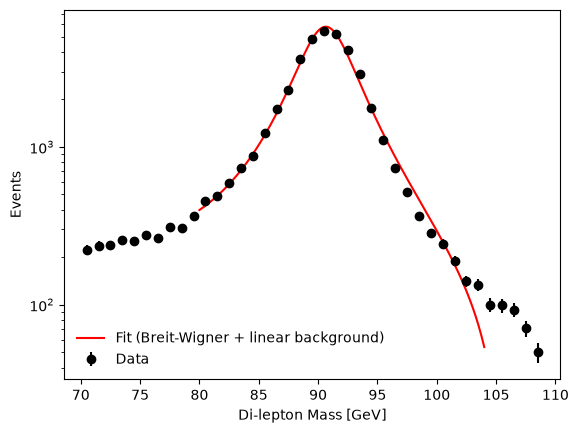

chi2/ndf = 225.3/19 = 11.86


In [10]:
fig, ax = plt.subplots()
ax.errorbar(bin_centres, counts, yerr=errors, fmt='ko', label='Data')
ax.plot(xs, model(xs, *popt), 'r-', label='Fit (Breit-Wigner + linear background)')
ax.set_yscale('log')
ax.set_xlabel('Di-lepton Mass [GeV]')
ax.set_ylabel('Events')
ax.legend(frameon=False)
fig.savefig('z_peak_fit.png', dpi=200)   # saved so you can put it on GitHub
plt.show()

# How good is the fit? (chi-squared per degree of freedom; ~1 means a good fit)
resid = (counts[mask] - model(bin_centres[mask], *popt)) / np.maximum(errors[mask], 1)
chi2 = np.sum(resid**2)
ndf = mask.sum() - 5
print(f"chi2/ndf = {chi2:.1f}/{ndf} = {chi2/ndf:.2f}")

In [11]:
for lo, hi in [(80, 104), (82, 100), (84, 98), (85, 97)]:
    m = (bin_centres > lo) & (bin_centres < hi)
    p, c = curve_fit(model, bin_centres[m], counts[m],
                     p0=[counts.max(), 91, 5, 300, -10],
                     sigma=np.maximum(errors[m], 1), absolute_sigma=True)
    r = (counts[m] - model(bin_centres[m], *p)) / np.maximum(errors[m], 1)
    print(f"fit range {lo}-{hi}: mass = {p[1]:.2f}, width = {p[2]:.2f}, "
          f"chi2/ndf = {np.sum(r**2)/(m.sum()-5):.1f}")

fit range 80-104: mass = 90.65, width = 5.16, chi2/ndf = 11.9
fit range 82-100: mass = 90.71, width = 5.51, chi2/ndf = 6.9
fit range 84-98: mass = 90.73, width = 5.85, chi2/ndf = 5.1
fit range 85-97: mass = 90.76, width = 6.04, chi2/ndf = 4.6


Mass       = 90.70 +/- 0.02 GeV
Resolution = 1.80 +/- 0.02 GeV
chi2/ndf   = 3.7


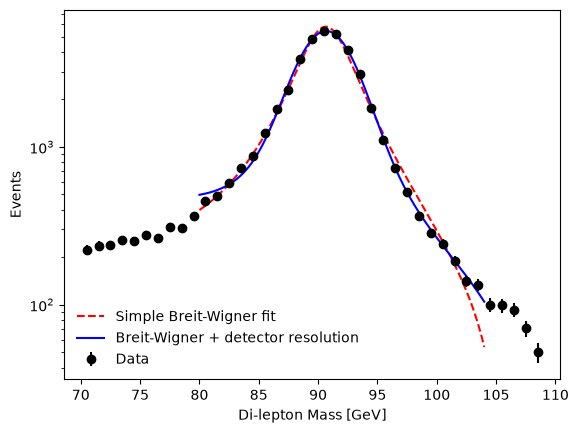

In [12]:
from scipy.special import voigt_profile

GAMMA_Z = 2.4952   # accepted natural width of the Z in GeV (PDG)

# Breit-Wigner (fixed natural width) blurred by a Gaussian of width sigma
def model_voigt(x, N, M, sigma, b0, b1):
    return N * voigt_profile(x - M, sigma, GAMMA_Z/2) + b0 + b1*(x - 90)

popt2, pcov2 = curve_fit(
    model_voigt, bin_centres[mask], counts[mask],
    p0=[counts.max()*3, 91, 2, 300, -10],
    sigma=np.maximum(errors[mask], 1), absolute_sigma=True,
)
perr2 = np.sqrt(np.diag(pcov2))
resid2 = (counts[mask] - model_voigt(bin_centres[mask], *popt2)) / np.maximum(errors[mask], 1)

print(f"Mass       = {popt2[1]:.2f} +/- {perr2[1]:.2f} GeV")
print(f"Resolution = {popt2[2]:.2f} +/- {perr2[2]:.2f} GeV")
print(f"chi2/ndf   = {np.sum(resid2**2)/(mask.sum()-5):.1f}")

fig, ax = plt.subplots()
ax.errorbar(bin_centres, counts, yerr=errors, fmt='ko', label='Data')
ax.plot(xs, model(xs, *popt), 'r--', label='Simple Breit-Wigner fit')
ax.plot(xs, model_voigt(xs, *popt2), 'b-', label='Breit-Wigner + detector resolution')
ax.set_yscale('log'); ax.set_xlabel('Di-lepton Mass [GeV]'); ax.set_ylabel('Events')
ax.legend(frameon=False)
fig.savefig('z_peak_fit_resolution.png', dpi=200)
plt.show()

## Results and Discussion

### 1. What I Measured

I analyzed the first file from Period D of the 2015 dataset to estimate the Z boson mass from the di-muon invariant mass distribution. I used a Breit-Wigner model with a linear background, varied the fitting range, and then included detector resolution to improve the fit.

| Fit | Mass (GeV) | Width / Resolution (GeV) | χ²/ndf |
|---|---|---|---|
| Breit-Wigner + linear background | 90.65 | Width: 5.16 | 11.9 |
| Breit-Wigner with varied fit range (82–100 to 85–97 GeV) | 90.71–90.76 | Width: 5.5–6.0 | 6.9–4.6 |
| Breit-Wigner with detector resolution | 90.70 ± 0.02 | Resolution: 1.80 ± 0.02 | 3.7 |

The results show a clear resonance peak near 91 GeV, consistent with the expected Z boson signal. Including detector resolution improved the fit quality, reducing χ²/ndf from 11.9 to 3.7.

### 2. How It Compares with the Accepted Values

The accepted Z boson mass is approximately 91.19 GeV, while my resolution fit gives 90.70 GeV. This is 0.49 GeV lower, a relative difference of approximately 0.54%. My initial fitted width of 5.16 GeV is considerably larger than the accepted natural width of approximately 2.50 GeV. In the resolution fit, I fixed the natural width to the accepted value and obtained a detector resolution of 1.80 GeV instead. Although the statistical mass uncertainty is ±0.02 GeV, I use approximately ±0.1 GeV as a conservative estimate of fitting-related uncertainty, based on how much the mass changed across fit ranges in the simple Breit-Wigner fit. I did not repeat the fit-range study for the resolution fit, and this estimate does not include possible calibration uncertainties.

### 3. Why My Numbers Differ

The initial fitted width is larger partly because the detector has limited energy and momentum resolution, which broadens the reconstructed mass distribution. My resolution fit estimates this smearing as 1.80 GeV. This assumes the natural width is 2.50 GeV, so it is not an independent measurement of it. The lower mass might result from photon radiation by the final-state muons or an uncalibrated detector response, but I did not test these effects separately. The resolution model describes the peak more accurately than the original fit, but its χ²/ndf of 3.7 remains above the ideal value of approximately 1. This indicates that the model still does not fully describe the data, so my results should be treated as preliminary estimates rather than a precision measurement.

### 4. Limitations

- I used only one of the 16 available data files from the 2015 dataset and did not compare my results with simulated events. This limits how well I can evaluate the reliability of the fit.
- I did not apply detector calibration or efficiency corrections. Possible systematic effects, particularly those affecting the reconstructed mass, are therefore not included in my quoted uncertainty.
- I used a simplified linear background and a single Gaussian detector-resolution model. I also fixed the natural Z boson width to its accepted value in the final fit, meaning that the natural width was not independently measured by that model.

# Part 3: From a fit to a measurement

In Part 2 I fitted the di-muon peak and got M_Z = 90.70 ± 0.02 GeV with χ²/ndf = 3.7, using a
χ² fit at bin centres with a linear background. Here I redo the measurement more rigorously
and test how robust it is:

1. **A likelihood fit** (extended binned Poisson likelihood, the method LHC analyses use)
   with the model integrated over each bin, an exponential background, and a **pull panel**.
2. **Fit-range systematic** for the resolution fit (Part 2 only did this for the simple fit).
3. **More data:** all 16 files of the 2015 run instead of one.
4. **A second channel:** Z → ee, and a comparison of ee vs μμ.

The fit code lives in `zfit.py` (numpy + scipy + matplotlib only).

In [13]:
# Get zfit.py from this repository when running in Colab
import os
if not os.path.exists("zfit.py"):
    !wget -q https://raw.githubusercontent.com/lujainalghamdi8105-dev/atlas-open-data-z-boson/main/zfit.py
import zfit
import numpy as np, awkward as ak, matplotlib.pyplot as plt

## 3.1 Likelihood fit on the same data as Part 2

This uses `full_mass_list` from Part 1, so the result can be compared directly with Part 2.
(If you run this notebook on its own, it falls back to a toy sample.)

124935 di-muon events, 44343 in 66-116 GeV
Fit result μμ
  M_Z    = 90.579 ± 0.017 GeV   (PDG 91.1879)
  sigma  = 1.979 ± 0.021 GeV   (detector resolution)
  Gamma  = 2.495  (fixed to PDG)
  N_sig  = 39234 ± 223
  N_bkg  = 5109 ± 125
  chi2/ndf = 598.7/95 = 6.30


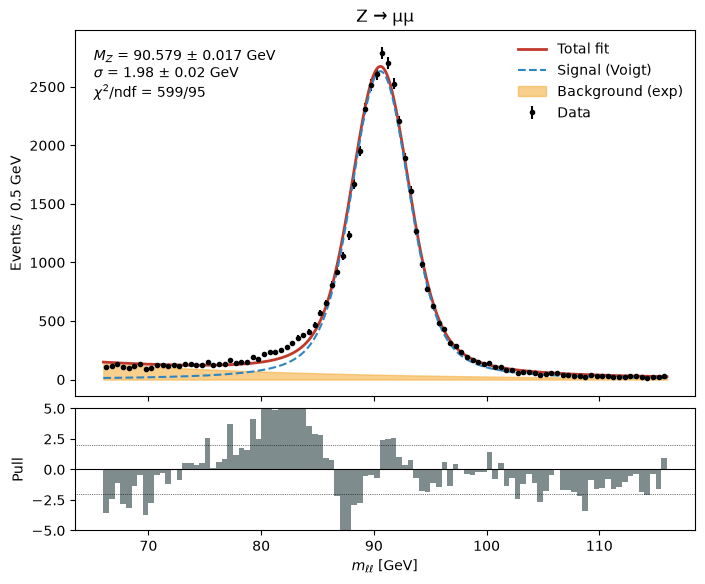

In [14]:
try:
    mll_mumu = ak.to_numpy(ak.flatten(full_mass_list, axis=None))
    USING_TOY = False
except NameError:
    USING_TOY = True
    rng = np.random.default_rng(1)
    bw = zfit.PDG_MZ + zfit.PDG_GZ/2*np.tan(np.pi*(rng.random(200000)-0.5))
    s = bw + rng.normal(0, 1.8, bw.size); s = s[(s>66)&(s<116)][:50000]
    u = rng.random(1500); b = 66 - np.log(1-u*(1-np.exp(-0.04*50)))/0.04
    mll_mumu = np.concatenate([s, b])
    print("Part 1 not run: using a TOY sample (true M = 91.1879, sigma = 1.8 GeV)")

print(f"{len(mll_mumu)} di-muon events, {np.sum((mll_mumu>66)&(mll_mumu<116))} in 66-116 GeV")
res_mumu = zfit.fit_z(mll_mumu, label="μμ")
zfit.summary(res_mumu)
fig = zfit.plot_fit(res_mumu); fig.savefig("z_fit_mumu_likelihood.png", dpi=200, bbox_inches="tight")
plt.show()

**Compare with Part 2:** does the mass move? Does the pull panel show a *pattern*?
A run of positive pulls on the low-mass side (≈ 75–88 GeV) is the fingerprint of
**final-state radiation**: a muon radiates a photon, so the measured mass comes out low.
A symmetric Voigt can't describe that tail, so the fit drags the peak position down to
compensate. That is one candidate explanation for the 0.49 GeV shift found in Part 2.

## 3.2 Fit-range systematic for the resolution fit

In [15]:
ranges = [(66, 116), (70, 110), (75, 105), (80, 102), (84, 98)]
masses = []
for lo, hi in ranges:
    r = zfit.fit_z(mll_mumu, lo=lo, hi=hi, nbins=int((hi-lo)/0.5))
    p, e = r["params"], r["errors"]
    masses.append(p["M"])
    print(f"{lo:>3}-{hi:<3} GeV:  M = {p['M']:.3f} ± {e['M']:.3f}   "
          f"sigma = {p['sigma']:.2f}   chi2/ndf = {r['chi2']/r['ndf']:.2f}")
print(f"\nSpread of M across ranges: {max(masses)-min(masses):.3f} GeV "
      f"→ use half of it, {(max(masses)-min(masses))/2:.3f} GeV, as a fit-range systematic")

 66-116 GeV:  M = 90.579 ± 0.017   sigma = 1.98   chi2/ndf = 6.30
 70-110 GeV:  M = 90.594 ± 0.017   sigma = 1.96   chi2/ndf = 6.29
 75-105 GeV:  M = 90.622 ± 0.017   sigma = 1.91   chi2/ndf = 5.49
 80-102 GeV:  M = 90.683 ± 0.018   sigma = 1.82   chi2/ndf = 2.64
 84-98  GeV:  M = 90.749 ± 0.021   sigma = 1.72   chi2/ndf = 1.60

Spread of M across ranges: 0.170 GeV → use half of it, 0.085 GeV, as a fit-range systematic


If the mass climbs toward 91.19 GeV as the window narrows around the peak, the low-side
tail is what's pulling it down. That's evidence for the FSR explanation rather than just a guess.

## 3.3 More data: all 16 files

In Part 1, delete the `break` at the end of the file loop, then re-run Part 1 and this section.
(Downloads take a while the first time; `cache=True` keeps the files afterwards.)
The statistical uncertainty should shrink by roughly √(events ratio). The *systematic* effects
(FSR, calibration) won't shrink, which is an important lesson in itself.

## 3.4 A second channel: Z → ee

Part 1 uses the `2muons` skim, so there are no electrons yet. Repeat the Part 1 loading
with the two-electron skim of the same release, compute `mll_ee` the same way, then run:

In [16]:
mll_ee = None   # e.g. ak.to_numpy(ak.flatten(ee_mass_list, axis=None))

if mll_ee is not None:
    res_ee = zfit.fit_z(mll_ee, label="ee")
    zfit.summary(res_ee)
    fig = zfit.plot_fit(res_ee); fig.savefig("z_fit_ee_likelihood.png", dpi=200, bbox_inches="tight")
    plt.show()
    zfit.compare_channels([res_ee, res_mumu])

**Questions for the write-up**
1. Do ee and μμ agree on M_Z? With each other, and with the PDG value (91.1879 ± 0.0020 GeV)?
2. Which channel has better resolution? Electrons are measured mainly in the **calorimeter**,
   muons in the **inner tracker + muon spectrometer**. Which should win for ~45 GeV leptons, and why?
3. Electrons radiate *much* more than muons (radiation scales as 1/m²). Does the ee peak show a
   bigger low-side tail?

## 3.5 Bonus: let the natural width float

In [17]:
res_free = zfit.fit_z(mll_mumu, label="μμ (free Γ)", fix_width=False)
zfit.summary(res_free)
i, j = res_free["names"].index("sigma"), res_free["names"].index("Gamma")
c = res_free["cov"]
print(f"\ncorrelation(sigma, Gamma) = {c[i,j]/np.sqrt(c[i,i]*c[j,j]):+.2f}")

Fit result μμ (free Γ)
  M_Z    = 90.578 ± 0.017 GeV   (PDG 91.1879)
  sigma  = 1.541 ± 0.048 GeV   (detector resolution)
  Gamma  = 3.448 ± 0.083 GeV   (PDG 2.4955)
  N_sig  = 40683 ± 254
  N_bkg  = 3660 ± 166
  chi2/ndf = 461.8/94 = 4.91

correlation(sigma, Gamma) = -0.86


A correlation near −1 means the data can trade "natural width" for "detector smearing" almost
freely. That's why Part 2 was right to fix Γ_Z to the PDG value.

## 3.6 Coming next: data vs. simulation
Compare the measured peak with ATLAS simulated Z → μμ events. If the simulation shows the same
low-side tail and the same shift, the shift is understood physics (FSR + detector), not a mistake.